# EDA (Exploratory Data Analysis)

**Датасет:** Wild Blueberry Yield Prediction (Kaggle).    
**Бизнес-задача:** «Моделирование урожайности дикой черники в агротехнике».    
**Описание кейса:** Необходимо определить итоговую массу урожая черники на основе характеристик участка, климатических условий в период цветения и показателей плотности четырех видов диких пчел-опылителей.

## **1.1 Бизнес-контекст**

### «Моделирование урожайности дикой черники в агротехнике»

**Задача:** Понять, какие характеристики подходят для построения модели.  
**Цель:** Построить модель, которая сможет предсказывать итоговую массу урожая, по выбранным характеристикам.

### Датасет Wild Blueberry Yield Prediction
- Набор данных, состоящий из 777 записей 
- Средний размер клонов голубики на участке.
- Плотность кормодобывающей активности каждой таксономической группы пчёл.
- Погодная информация, включая температуру, осадки и скорость ветра.
- Источник: Университет штата Мэн, США

###  Описание данных

- Набор данных, использованный для прогнозного моделирования, был создан с помощью модели опыления дикой голубики, которая представляет собой программу компьютерного моделирования с открытым исходным кодом и пространственным анализом, которая позволяет изучить, как различные факторы, в том числе пространственное расположение растений, перекрестное и самоопыление, видовой состав пчел и погодные условия, по отдельности и в сочетании, влияют на эффективность опыления и урожайность агроэкосистемы дикой голубики. Имитационная модель была проверена с помощью полевых наблюдений и экспериментальных данных, собранных в штате Мэн, США, и Приморских провинциях Канады за последние 30 лет.
- Всего было проведено 77 700 симуляций, чтобы обеспечить как обширную, так и интенсивную выборку, в результате чего был получен набор данных, состоящий из 777 записей, каждая из которых представляет собой в среднем 100 симуляцийпрогонов.
- Количество пространственных выборок внутри каждого фактора: 6 уровней для размера клона; 7 уровней для плотности медоносных пчел; 10 уровней для плотности шмелей; 12 уровней для плотности пчел Andrena и Osmia соответственно; 3 уровня для температуры воздуха и осадков соответственно.
- Создали четыре климатических условия: «тепло и сухо», «тепло и влажно», «прохладно и сухо», «прохладно и влажно» соответственно.

## **1.2 Импорты и настройки**

In [6]:
!python -m pip install --upgrade pip

  Using cached pip-26.3-py3-none-any.whl.metadata (4.6 kB)
Using cached pip-26.3-py3-none-any.whl (2.0 MB)
  Attempting uninstall: pip
    Found existing installation: pip 24.0
    Uninstalling pip-24.0:
      Successfully uninstalled pip-24.0


In [13]:
!pip install matplotlib seaborn pandas numpy kagglehub


   ---------------------------------------- 0/4 [tqdm]
   ---------------------------------------- 0/4 [tqdm]
   ---------------------------------------- 0/4 [tqdm]
   ---------- ----------------------------- 1/4 [protobuf]
   ---------- ----------------------------- 1/4 [protobuf]
   ---------- ----------------------------- 1/4 [protobuf]
   ---------- ----------------------------- 1/4 [protobuf]
   ---------- ----------------------------- 1/4 [protobuf]
   ---------- ----------------------------- 1/4 [protobuf]
   -------------------- ------------------- 2/4 [kagglesdk]
   -------------------- ------------------- 2/4 [kagglesdk]
   -------------------- ------------------- 2/4 [kagglesdk]
   -------------------- ------------------- 2/4 [kagglesdk]
   -------------------- ------------------- 2/4 [kagglesdk]
   -------------------- ------------------- 2/4 [kagglesdk]
   -------------------- ------------------- 2/4 [kagglesdk]
   -------------------- ------------------- 2/4 [kagglesdk]


In [1]:
# Основные библиотеки
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import pi

# Загрузка данных
import kagglehub
from kagglehub import KaggleDatasetAdapter

## **1.3 Загрузка данных**

In [4]:
# Download latest version
path = kagglehub.dataset_download("saurabhshahane/wild-blueberry-yield-prediction")


In [3]:
# Загрузка датасета с Kaggle
path = kagglehub.dataset_download("saurabhshahane/wild-blueberry-yield-prediction")
df = pd.read_csv(f"{path}/WildBlueberryPollinationSimulationData.csv", index_col=0)

### 📋 Описание столбцов датасета

| Столбец | Тип | Описание |
|---------|-----|----------|
| **clonesize** | float64 | Средний размер клона голубики в поле (м²), площади, занимаемой группой кустов голубики |
| **honeybee** | float64 | Плотность медоносных пчёл в поле (пчёл/м²·мин), усреднённый показатель активности опылителей, количество пчёл на квадратный метр в минуту |
| **bumbles** | float64 | Плотность шмелей в поле (пчёл/м²·минн) |
| **andrena** | float64 | Плотность пчёл-андрен в поле (пчёл/м²·мин) |
| **osmia** | float64 | Плотность пчёл-осмий в поле (пчёл/м²·мин) |
| **MaxOfUpperTRange** | float64 | Максимум дневной температуры в «верхнем» диапазоне в период цветения (°F) |
| **MinOfUpperTRange** | float64 | Минимум дневной температуры в «верхнем» диапазоне (°F) |
| **AverageOfUpperTRange** | float64 | Средняя дневная температура «верхнего» диапазона (°F) |
| **MaxOfLowerTRange** | float64 | Максимум дневной температуры в «нижнем» диапазоне (°F) |
| **MinOfLowerTRange** | float64 | Минимум дневной температуры в «нижнем» диапазоне (°F) |
| **AverageOfLowerTRange** | float64 | Средняя дневная температура «нижнего» диапазона (°F) |
| **RainingDays** | float64 | Общее число дождливых дней за весь сезон цветения (дней) |
| **AverageRainingDays** | float64 | Среднее число дождливых дней за весь период цветения (дюймы), 0,06 «дня» не бывает, а вот 1,5–14 мм осадков — вполне  |
| **fruitset** | float64 | Показатель завязываемости плодов (переход к стадии завязи) (доля) |
| **fruitmass** | float64 | Масса плода (г) |
| **seeds** | float64 | Число семян в плоде (шт) |
| **yield** | float64 | Урожайность, урожай голубики (целевая переменная) (кг/га) |



---

# **Часть 2. Первичный осмотр данных**

## **2.1 Первый взгляд на данные**

In [5]:
# Посмотрим статистику по столбцу
print(df['honeybee'].describe())

# Посмотрим уникальные значения или первые 20 строк
print(df['honeybee'].unique())
print(df[['honeybee']].head(20))

count    777.000000
mean       0.417133
std        0.978904
min        0.000000
25%        0.250000
50%        0.250000
75%        0.500000
max       18.430000
Name: honeybee, dtype: float64
[ 0.75   0.25   0.5    0.     6.64  18.43   0.537]
      honeybee
Row#          
0         0.75
1         0.75
2         0.75
3         0.75
4         0.75
5         0.75
6         0.75
7         0.75
8         0.75
9         0.75
10        0.75
11        0.25
12        0.25
13        0.25
14        0.25
15        0.25
16        0.25
17        0.25
18        0.25
19        0.25


In [11]:
# Первые 5 строк
df.head(5)

,clonesize,honeybee,bumbles,andrena,osmia,MaxOfUpperTRange,MinOfUpperTRange,AverageOfUpperTRange,MaxOfLowerTRange,MinOfLowerTRange,AverageOfLowerTRange,RainingDays,AverageRainingDays,fruitset,fruitmass,seeds,yield
Row#,,,,,,,,,,,,,,,,,
0,37.5,0.75,0.25,0.25,0.25,86.0,52.0,71.9,62.0,30.0,50.8,16.0,0.26,0.410652,0.408159,31.678898,3813.165795
1,37.5,0.75,0.25,0.25,0.25,86.0,52.0,71.9,62.0,30.0,50.8,1.0,0.10,0.444254,0.425458,33.449385,4947.605663
2,37.5,0.75,0.25,0.25,0.25,94.6,57.2,79.0,68.2,33.0,55.9,16.0,0.26,0.383787,0.399172,30.546306,3866.798965
3,37.5,0.75,0.25,0.25,0.25,94.6,57.2,79.0,68.2,33.0,55.9,1.0,0.10,0.407564,0.408789,31.562586,4303.943030
4,37.5,0.75,0.25,0.25,0.25,86.0,52.0,71.9,62.0,30.0,50.8,24.0,0.39,0.354413,0.382703,28.873714,3436.493543


In [12]:
# Случайная выборка — всегда смотрите разные срезы!
df.sample(5, random_state=42)

,clonesize,honeybee,bumbles,andrena,osmia,MaxOfUpperTRange,MinOfUpperTRange,AverageOfUpperTRange,MaxOfLowerTRange,MinOfLowerTRange,AverageOfLowerTRange,RainingDays,AverageRainingDays,fruitset,fruitmass,seeds,yield
Row#,,,,,,,,,,,,,,,,,
568,25.0,0.50,0.25,0.63,0.50,69.7,42.1,58.2,50.2,24.3,41.2,34.0,0.56,0.388956,0.376880,29.284336,4282.700632
530,25.0,0.50,0.25,0.50,0.63,77.4,46.8,64.7,55.8,27.0,45.8,1.0,0.10,0.532729,0.466475,38.060375,6801.492050
610,25.0,0.50,0.25,0.75,0.50,77.4,46.8,64.7,55.8,27.0,45.8,1.0,0.10,0.510669,0.452680,36.386359,6279.338501
109,12.5,0.25,0.25,0.25,0.63,69.7,42.1,58.2,50.2,24.3,41.2,16.0,0.26,0.546136,0.453001,37.970243,6898.390949
586,25.0,0.50,0.25,0.63,0.75,86.0,52.0,71.9,62.0,30.0,50.8,1.0,0.10,0.542164,0.471829,38.705696,7004.015537


In [40]:
# Посмотрим последние строки
df.tail(5)

,clonesize,honeybee,bumbles,andrena,osmia,MaxOfUpperTRange,MinOfUpperTRange,AverageOfUpperTRange,MaxOfLowerTRange,MinOfLowerTRange,AverageOfLowerTRange,RainingDays,AverageRainingDays,fruitset,fruitmass,seeds,yield
Row#,,,,,,,,,,,,,,,,,
772,10.0,0.537,0.117,0.409,0.058,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.486815,0.428012,33.447471,5333.873335
773,40.0,0.537,0.117,0.409,0.058,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.342841,0.377915,28.462005,3373.436842
774,20.0,0.537,0.117,0.409,0.058,86.0,52.0,71.9,62.0,30.0,50.8,24.00,0.39,0.404617,0.401670,30.748240,4203.027624
775,20.0,0.537,0.117,0.409,0.058,89.0,39.0,65.6,66.0,28.0,45.3,3.77,0.06,0.401538,0.399935,30.582161,4166.299735
776,20.0,0.537,0.117,0.409,0.058,89.0,39.0,65.6,66.0,28.0,45.3,24.00,0.39,0.384646,0.392303,29.742583,3943.131681


#### **Вывод**
В последних строках присутствуют дробные значения кол-ва дождевый дней: 3.77. Нужно проверить.

## **2.2 Технический паспорт данных**

In [37]:
# Информация о структуре
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 777 entries, 0 to 776
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   clonesize             777 non-null    float64
 1   honeybee              777 non-null    float64
 2   bumbles               777 non-null    float64
 3   andrena               777 non-null    float64
 4   osmia                 777 non-null    float64
 5   MaxOfUpperTRange      777 non-null    float64
 6   MinOfUpperTRange      777 non-null    float64
 7   AverageOfUpperTRange  777 non-null    float64
 8   MaxOfLowerTRange      777 non-null    float64
 9   MinOfLowerTRange      777 non-null    float64
 10  AverageOfLowerTRange  777 non-null    float64
 11  RainingDays           777 non-null    float64
 12  AverageRainingDays    777 non-null    float64
 13  fruitset              777 non-null    float64
 14  fruitmass             777 non-null    float64
 15  seeds                 777 no

In [7]:
# Анализ типов данных
df.dtypes.value_counts()

float64    17
Name: count, dtype: int64

### Анализ `.info()`:

| Метрика | Значение | Вывод |
|---------|----------|-------|
| **Типы данных** | float64(17) | OK, но можно оптимизировать |
| **Пропуски** | Нет | Пропусков нет |


## **2.3 Оптимизация памяти**
Теперь, когда данные очищены, можно оптимизировать типы данных для экономии памяти.

In [13]:
# Замер памяти до оптимизации
memory_before = df.memory_usage(deep=True).sum() / 1024**2
print(f"Память до: {memory_before:.2f} MB")

Память до: 0.10 MB


In [14]:
# Числовые типы
# выбрать атоматически
float_cols = df.select_dtypes(include=['float64']).columns

for col in float_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], downcast='float')

# Замер памяти после оптимизации
memory_after = df.memory_usage(deep=True).sum() / 1024**2
print(f"\nПамять после: {memory_after:.2f} MB")
print(f"📉 Экономия: {(1 - memory_after/memory_before)*100:.1f}%")


Память после: 0.05 MB
📉 Экономия: 49.9%


In [15]:
# Анализ типов данных
df.dtypes.value_counts()

float32    17
Name: count, dtype: int64

#### **Вывод**
Данные были оптимизированы, стали float32, что уменьшило размер, занимаего пространства с 0,11 до 0,06 МВ, в этом датасете это не имеет значения, просто чтобы запомнить.

## **2.4 Статистическая сводка**

Смотрим статистические даные вместе с пропусками, кол-во уникальных значений и есть ли асимметрия

In [38]:
# Расширенная описательная статистика
stats = df.describe().T

stats['missing'] = df.isna().sum()
stats['unique'] = df.nunique()
stats['skew'] = df.skew()
stats['kurtosis'] = df.kurtosis()

display(stats.round(3))

,count,mean,std,min,25%,50%,75%,max,missing,unique,skew,kurtosis
clonesize,777.0,18.768,6.999,10.000,12.500,12.500,25.000,40.000,0,6,0.575,-0.626000
honeybee,777.0,0.417,0.979,0.000,0.250,0.250,0.500,18.430,0,7,16.761,299.011993
bumbles,777.0,0.282,0.066,0.000,0.250,0.250,0.380,0.585,0,10,0.153,1.707000
andrena,777.0,0.469,0.161,0.000,0.380,0.500,0.630,0.750,0,12,0.187,-0.662000
osmia,777.0,0.562,0.169,0.000,0.500,0.630,0.750,0.750,0,12,-0.919,0.556000
MaxOfUpperTRange,777.0,82.277,9.194,69.700,77.400,86.000,89.000,94.600,0,5,-0.012,-1.348000
MinOfUpperTRange,777.0,49.701,5.596,39.000,46.800,52.000,52.000,57.200,0,5,-0.016,-1.339000
AverageOfUpperTRange,777.0,68.723,7.677,58.200,64.700,71.900,71.900,79.000,0,5,-0.017,-1.346000
MaxOfLowerTRange,777.0,59.309,6.648,50.200,55.800,62.000,66.000,68.200,0,5,-0.017,-1.348000
MinOfLowerTRange,777.0,28.690,3.210,24.300,27.000,30.000,30.000,33.000,0,5,-0.009,-1.343000


In [24]:
# Смотрим уникальные значения по усредненным характеристикам
unic = ["clonesize", "honeybee", "bumbles", "andrena", "osmia", "RainingDays", "AverageRainingDays",
       "MaxOfUpperTRange", "MinOfUpperTRange", "AverageOfUpperTRange", "MaxOfLowerTRange", "MinOfLowerTRange",
       "AverageOfLowerTRange"]

print("Уникальные значения для усредненных категорий")
for i in unic:
    print(f"{i} : {df[i].unique()}")

Уникальные значения для усредненных категорий
clonesize : [37.5 25.  12.5 20.  10.  40. ]
honeybee : [ 0.75   0.25   0.5    0.     6.64  18.43   0.537]
bumbles : [0.25  0.38  0.117 0.202 0.    0.065 0.042 0.585 0.293 0.058]
andrena : [0.25  0.38  0.5   0.63  0.75  0.409 0.707 0.    0.229 0.147 0.585 0.234]
osmia : [0.25  0.38  0.5   0.63  0.75  0.058 0.101 0.    0.033 0.021 0.585 0.117]
RainingDays : [16.    1.   24.   34.    3.77]
AverageRainingDays : [0.26 0.1  0.39 0.56 0.06]
MaxOfUpperTRange : [86.  94.6 77.4 69.7 89. ]
MinOfUpperTRange : [52.  57.2 46.8 42.1 39. ]
AverageOfUpperTRange : [71.9 79.  64.7 58.2 65.6]
MaxOfLowerTRange : [62.  68.2 55.8 50.2 66. ]
MinOfLowerTRange : [30.  33.  27.  24.3 28. ]
AverageOfLowerTRange : [50.8 55.9 45.8 41.2 45.3]


### Вывод
- **Пропуски** отсутствуют.
- **Уникальность значений:**
    - 'clonesize'- по 6 значений,
    - 'honeybee' - по 7 значений,
    - 'bumbles' - по 10 значений,
    - 'andrena', 'osmia' - по 12 значений,
    - 'MaxOfUpperTRange', 'MinOfUpperTRange', 'AverageOfUpperTRange', 'MaxOfLowerTRange', 'MinOfLowerTRange', 'AverageOfLowerTRange','RainingDays', 'AverageRainingDays' по  5 уникальных значений.  
Данные действительное были усреднены и теперь представляют несколько наборов усредненных значений. Погодные категории представлены 5 вариантами (в статье говорится про 4).
- **Асимметрия распределения:** у "honeybee" сильный скос вправо.
- **Эксцесс распределения** у "honeybee" очень тяжелый хвост, остальные вышеописанные тоже требуют детального рассмотрения
- Есть нулевые значения.
- У "honeybee" есть выбивающиеся значения: 6.64, 18.43 (как буд-то другая модель данных).
- "RainingDays" - единственное дробное значение.

In [39]:
print(df.columns)

Index(['clonesize', 'honeybee', 'bumbles', 'andrena', 'osmia',
       'MaxOfUpperTRange', 'MinOfUpperTRange', 'AverageOfUpperTRange',
       'MaxOfLowerTRange', 'MinOfLowerTRange', 'AverageOfLowerTRange',
       'RainingDays', 'AverageRainingDays', 'fruitset', 'fruitmass', 'seeds',
       'yield'],
      dtype='str')


In [108]:
# Смотрим подозрительные строки данных с определенными значениями
df_issue = df[np.isclose(df["RainingDays"], 3.77) | np.isclose(df["honeybee"], 18.43) | np.isclose(df["honeybee"], 6.64)]
display(df_issue)
print(f"Количество подозрительных строк: {len(df_issue)}")

# Как можно записать по другому
# col1 = np.isclose(df["RainingDays"], 3.77)
# col2 = np.isclose(df["honeybee"], 18.43) | np.isclose(df["honeybee"], 6.64)
# filter_df = df[col1 | col2]
# print(filter_df)
# print(f"Количество подозрительных строк: {len(filter_df)}")


,clonesize,honeybee,bumbles,andrena,osmia,MaxOfUpperTRange,MinOfUpperTRange,AverageOfUpperTRange,MaxOfLowerTRange,MinOfLowerTRange,AverageOfLowerTRange,RainingDays,AverageRainingDays,fruitset,fruitmass,seeds,yield
Row#,,,,,,,,,,,,,,,,,
759,20.0,0.000,0.117,0.409,0.058,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.380852,0.396044,30.052521,3923.906282
760,20.0,0.000,0.202,0.707,0.101,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.492760,0.443520,35.311957,5718.408168
761,20.0,6.640,0.000,0.000,0.000,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.508675,0.336240,24.601741,4936.364770
762,20.0,18.430,0.000,0.000,0.000,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.559628,0.364937,27.106391,6131.309380
763,20.0,6.640,0.065,0.229,0.033,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.539256,0.382997,28.887120,5686.121958
764,20.0,0.537,0.117,0.409,0.058,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.408178,0.403205,30.906861,4225.961314
765,20.0,18.430,0.042,0.147,0.021,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.557885,0.377597,28.556417,6276.410544
766,20.0,0.000,0.042,0.147,0.021,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.192732,0.311921,22.079199,1637.704022
767,20.0,0.000,0.585,0.000,0.000,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.599984,0.529791,46.585105,7575.801245


Количество подозрительных строк: 16


In [109]:
# Выделяем подозрительные строки в отдельный датасет и смотрим по нему статистику
df_extreme = df.tail(18)
df_extreme[["honeybee", "bumbles", "andrena", "osmia", 'RainingDays', 
        'MaxOfUpperTRange', 'MinOfUpperTRange', 'MaxOfLowerTRange', 'MinOfLowerTRange']].describe().T

,count,mean,std,min,25%,50%,75%,max
honeybee,18.0,2.964556,5.995315,0.00,0.000,0.537,0.537,18.430
bumbles,18.0,0.117000,0.139203,0.00,0.042,0.117,0.117,0.585
andrena,18.0,0.295611,0.211130,0.00,0.147,0.409,0.409,0.707
osmia,18.0,0.074556,0.131718,0.00,0.021,0.058,0.058,0.585
RainingDays,18.0,6.017778,6.541994,3.77,3.770,3.770,3.770,24.000
MaxOfUpperTRange,18.0,86.333333,0.970143,86.00,86.000,86.000,86.000,89.000
MinOfUpperTRange,18.0,50.555556,4.203951,39.00,52.000,52.000,52.000,52.000
MaxOfLowerTRange,18.0,62.444444,1.293523,62.00,62.000,62.000,62.000,66.000
MinOfLowerTRange,18.0,29.777778,0.646762,28.00,30.000,30.000,30.000,30.000


In [71]:
# Смотрим уникальные значения по усредненным характеристикам выделенного фрагмента датасета
unic = ["clonesize", "honeybee", "bumbles", "andrena", "osmia", "RainingDays", "AverageRainingDays",
       "MaxOfUpperTRange", "MinOfUpperTRange", "AverageOfUpperTRange", "MaxOfLowerTRange", "MinOfLowerTRange",
       "AverageOfLowerTRange"]

print("Уникальные значения для усредненных категорий")
for i in unic:
    print(f"{i} : {df_extreme[i].unique()}")

Уникальные значения для усредненных категорий
clonesize : [20. 10. 40.]
honeybee : [ 0.     6.64  18.43   0.537]
bumbles : [0.117 0.202 0.    0.065 0.042 0.585 0.293 0.058]
andrena : [0.409 0.707 0.    0.229 0.147 0.585 0.234]
osmia : [0.058 0.101 0.    0.033 0.021 0.585 0.117]
RainingDays : [ 3.77 24.  ]
AverageRainingDays : [0.06 0.39]
MaxOfUpperTRange : [86. 89.]
MinOfUpperTRange : [52. 39.]
AverageOfUpperTRange : [71.9 65.6]
MaxOfLowerTRange : [62. 66.]
MinOfLowerTRange : [30. 28.]
AverageOfLowerTRange : [50.8 45.3]


In [110]:
# Расширенная описательная статистика
stats_18 = df_extreme.describe().T

stats_18['unique'] = df_extreme.nunique()
stats_18['skew'] = df_extreme.skew()
stats_18['kurtosis'] = df_extreme.kurtosis()

display(stats_18.round(3))

,count,mean,std,min,25%,50%,75%,max,unique,skew,kurtosis
clonesize,18.0,20.556,5.393,10.000,20.000,20.000,20.000,40.000,3,2.604,11.783
honeybee,18.0,2.965,5.995,0.000,0.000,0.537,0.537,18.430,4,2.212,3.888
bumbles,18.0,0.117,0.139,0.000,0.042,0.117,0.117,0.585,8,2.477,7.508
andrena,18.0,0.296,0.211,0.000,0.147,0.409,0.409,0.707,7,-0.034,-0.721
osmia,18.0,0.075,0.132,0.000,0.021,0.058,0.058,0.585,7,3.794,15.334
MaxOfUpperTRange,18.0,86.333,0.970,86.000,86.000,86.000,86.000,89.000,2,2.706,5.977
MinOfUpperTRange,18.0,50.556,4.204,39.000,52.000,52.000,52.000,52.000,2,-2.706,5.977
AverageOfUpperTRange,18.0,71.200,2.037,65.600,71.900,71.900,71.900,71.900,2,-2.706,5.977
MaxOfLowerTRange,18.0,62.444,1.294,62.000,62.000,62.000,62.000,66.000,2,2.706,5.977
MinOfLowerTRange,18.0,29.778,0.647,28.000,30.000,30.000,30.000,30.000,2,-2.706,5.977


#### **Вывод**
Похоже эти данные принадлежат другой модели или моделируют какие-то особено экстремальные условия. 
- **Решение:** разделить датасет на два, основной и дополнительный, с этим набором данных.

In [185]:
df_base = df

In [186]:
df_base = df.drop(df_extreme.index)

In [187]:
df_base.info()

<class 'pandas.core.frame.DataFrame'>
Index: 759 entries, 0 to 758
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   clonesize             759 non-null    float64
 1   honeybee              759 non-null    float64
 2   bumbles               759 non-null    float64
 3   andrena               759 non-null    float64
 4   osmia                 759 non-null    float64
 5   MaxOfUpperTRange      759 non-null    float64
 6   MinOfUpperTRange      759 non-null    float64
 7   AverageOfUpperTRange  759 non-null    float64
 8   MaxOfLowerTRange      759 non-null    float64
 9   MinOfLowerTRange      759 non-null    float64
 10  AverageOfLowerTRange  759 non-null    float64
 11  RainingDays           759 non-null    float64
 12  AverageRainingDays    759 non-null    float64
 13  fruitset              759 non-null    float64
 14  fruitmass             759 non-null    float64
 15  seeds                 759 no

In [122]:
# Расширенная описательная статистика
stats_ = df_base.describe().T

stats_['unique'] = df_base.nunique()
stats_['skew'] = df_base.skew()
stats_['kurtosis'] = df_base.kurtosis()

display(stats_.round(3))

,count,mean,std,min,25%,50%,75%,max,unique,skew,kurtosis
clonesize,759.0,18.725,7.030,12.500,12.500,12.500,25.000,37.500,3,0.565,-0.712
honeybee,759.0,0.357,0.131,0.250,0.250,0.250,0.500,0.750,3,0.599,-0.979
bumbles,759.0,0.286,0.058,0.250,0.250,0.250,0.380,0.380,2,0.986,-1.031
andrena,759.0,0.473,0.158,0.250,0.380,0.500,0.630,0.750,5,0.292,-0.904
osmia,759.0,0.574,0.152,0.250,0.500,0.630,0.750,0.750,5,-0.627,-0.373
MaxOfUpperTRange,759.0,82.181,9.280,69.700,77.400,86.000,94.600,94.600,4,0.017,-1.372
MinOfUpperTRange,759.0,49.680,5.625,42.100,46.800,52.000,57.200,57.200,4,0.012,-1.370
AverageOfUpperTRange,759.0,68.664,7.752,58.200,64.700,71.900,79.000,79.000,4,0.005,-1.373
MaxOfLowerTRange,759.0,59.235,6.706,50.200,55.800,62.000,68.200,68.200,4,0.012,-1.370
MinOfLowerTRange,759.0,28.664,3.242,24.300,27.000,30.000,33.000,33.000,4,0.014,-1.371


In [116]:
df_base["RainingDays"].unique()

array([16.,  1., 24., 34.])

#### Вывод
- Теперь в базовом датасете, как и заявлено в статье, четыре климатических уровня. Нулевые значения отсутствуют.

# Часть 3. Качество данных

## 3.1 Пропуски данных
- пропуски отсутствуют

## 3.2 Поиск дубликатов

In [103]:
# Полные дубликаты
full_duplicates = df.duplicated().sum()
print(f"Полных дубликатов: {full_duplicates:,}")

Полных дубликатов: 0


#### Вывод
- дубликаты отсутсвуют

## **3.2 Анализ выбросов**

### **Визуальный метод: boxplot**

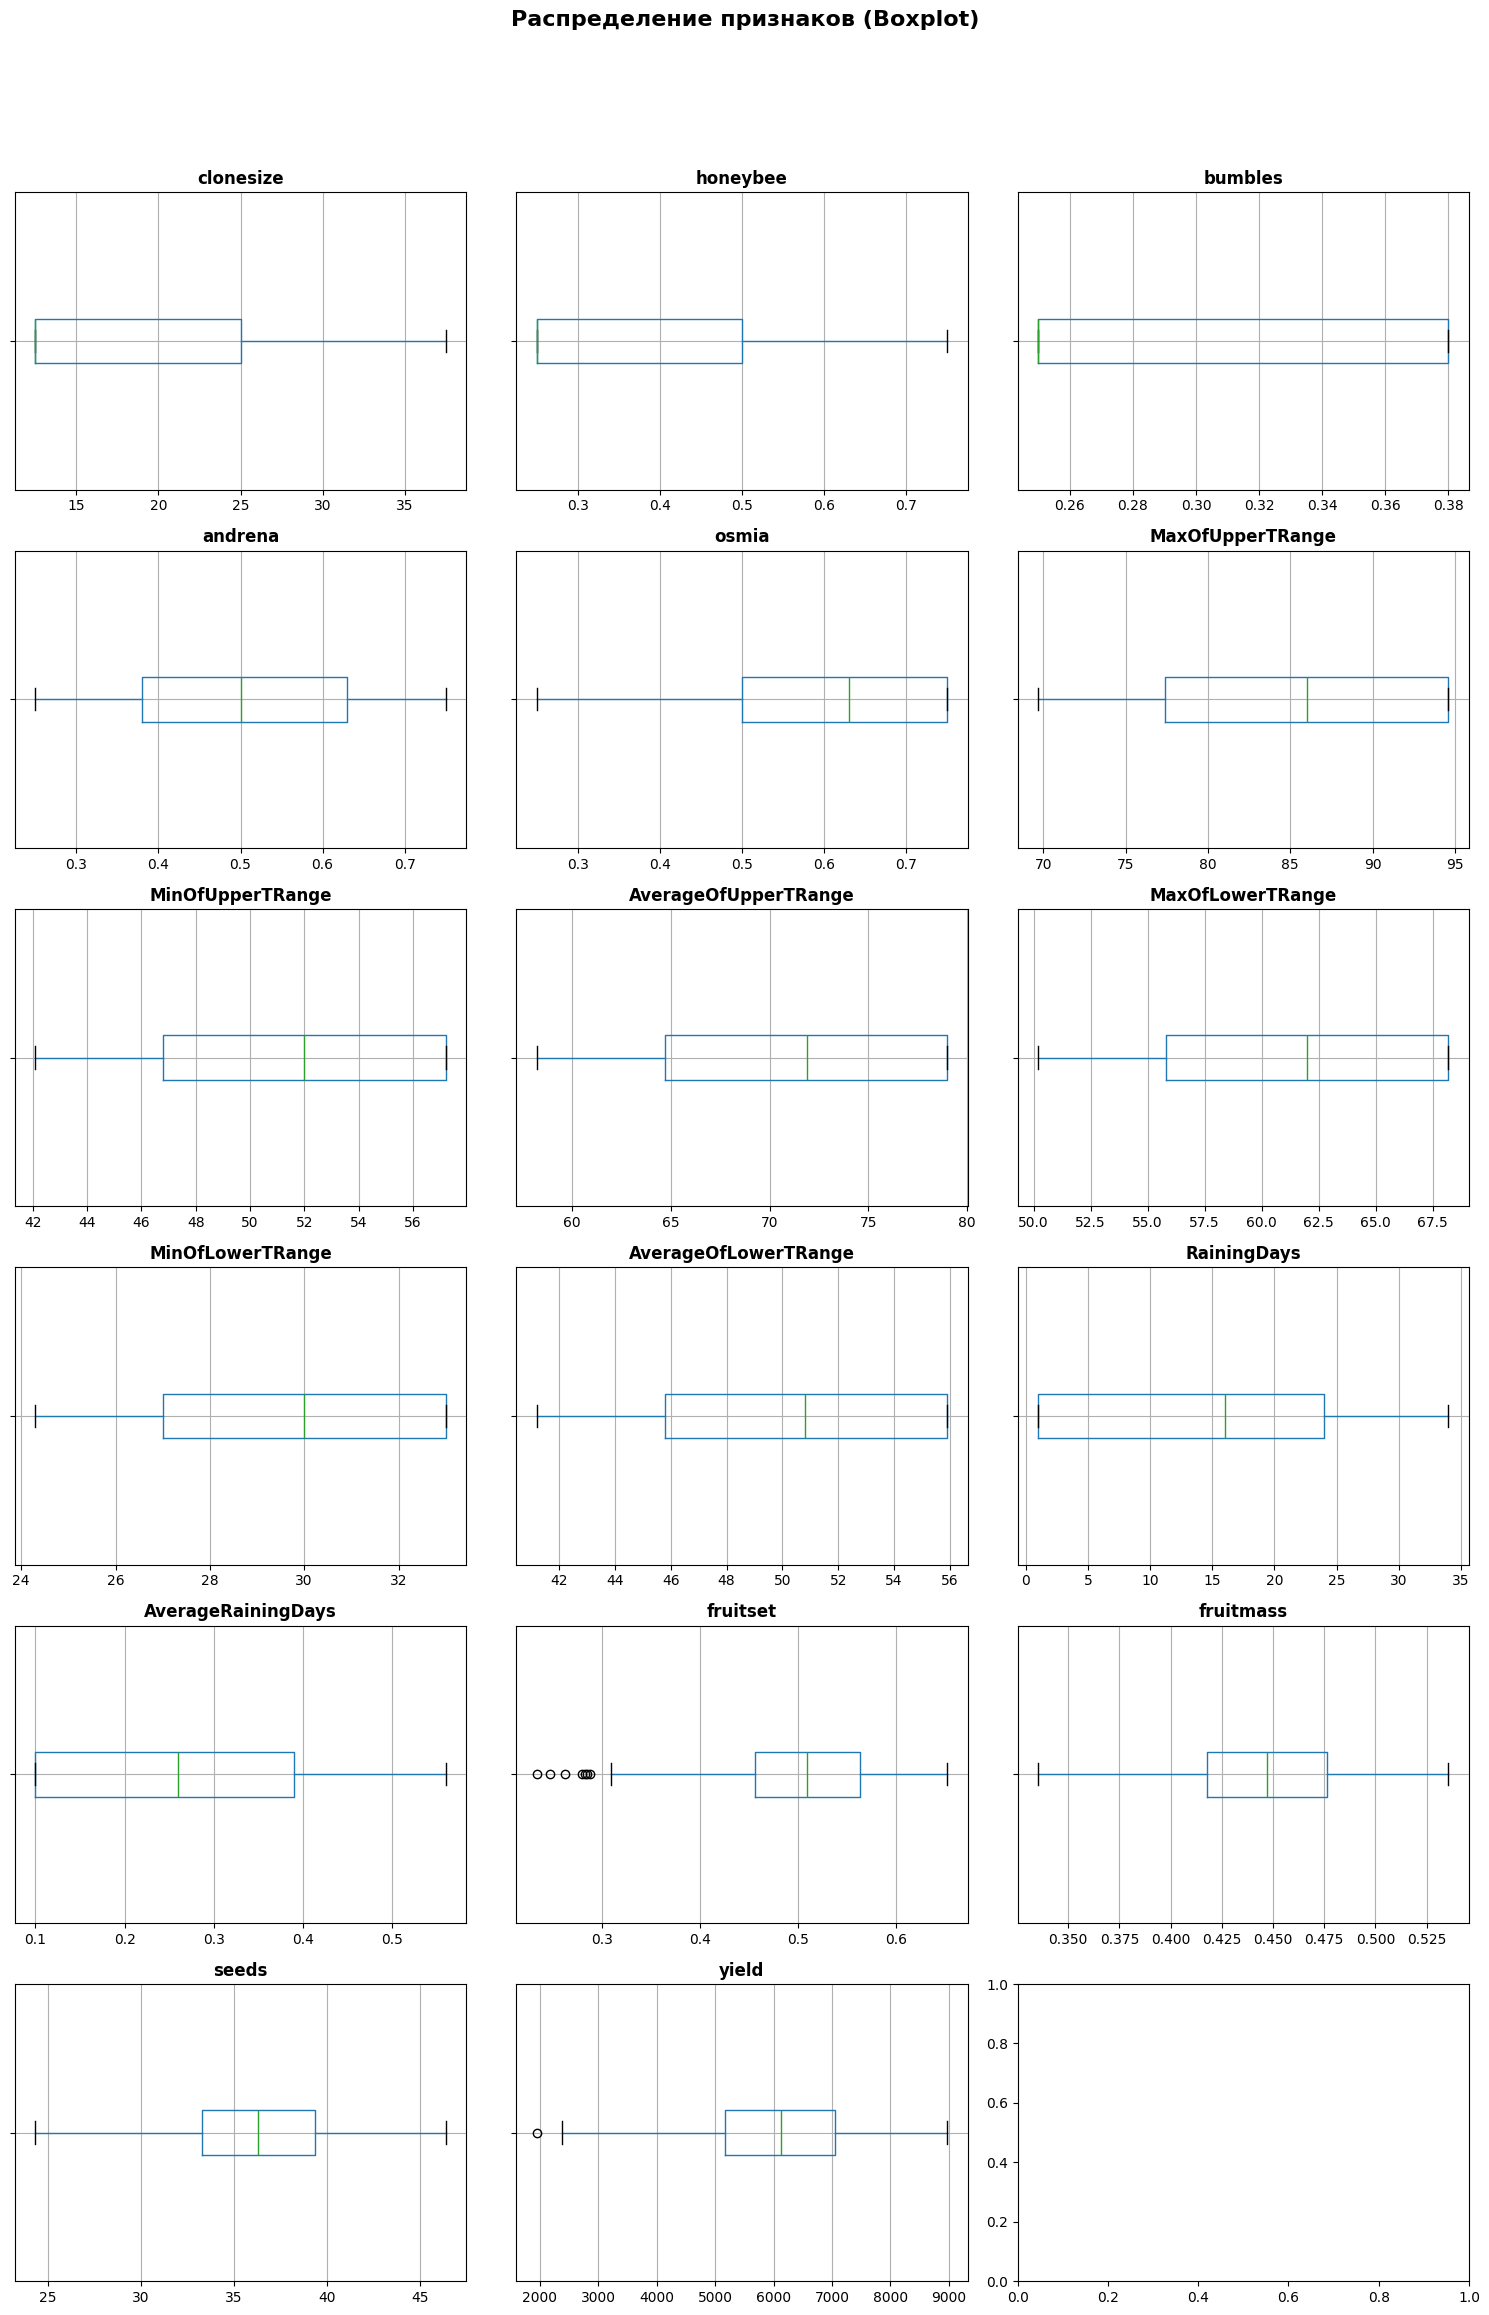

In [120]:
# Aнализа выбросов среди пчел

# Boxplot
fig, axes = plt.subplots(6, 3, figsize=(15, 22))
axes = axes.flatten()

for idx, col in enumerate(df_base):
    ax = axes[idx]
    df_base.boxplot(column=col, ax=ax, vert=False)
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.set_yticklabels([])

plt.suptitle('Распределение признаков (Boxplot)', fontsize=16, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

In [119]:
df_issue = df_base[np.isclose(df_base["RainingDays"], 3.77) | np.isclose(df_base["honeybee"], 18.43) | np.isclose(df_base["honeybee"], 6.64)]
display(df_issue)

,clonesize,honeybee,bumbles,andrena,osmia,MaxOfUpperTRange,MinOfUpperTRange,AverageOfUpperTRange,MaxOfLowerTRange,MinOfLowerTRange,AverageOfLowerTRange,RainingDays,AverageRainingDays,fruitset,fruitmass,seeds,yield
Row#,,,,,,,,,,,,,,,,,


**Выводы**
- выбросы за пределами усов отсутствуют у всех, кроме "fruitset" и "yield".


## 3.3 Проверка на избыточность

In [126]:
print(df_base.nunique().sort_values())

bumbles                   2
clonesize                 3
honeybee                  3
MaxOfUpperTRange          4
AverageOfUpperTRange      4
MinOfUpperTRange          4
MinOfLowerTRange          4
MaxOfLowerTRange          4
AverageRainingDays        4
RainingDays               4
AverageOfLowerTRange      4
andrena                   5
osmia                     5
fruitset                759
fruitmass               759
seeds                   759
yield                   759
dtype: int64


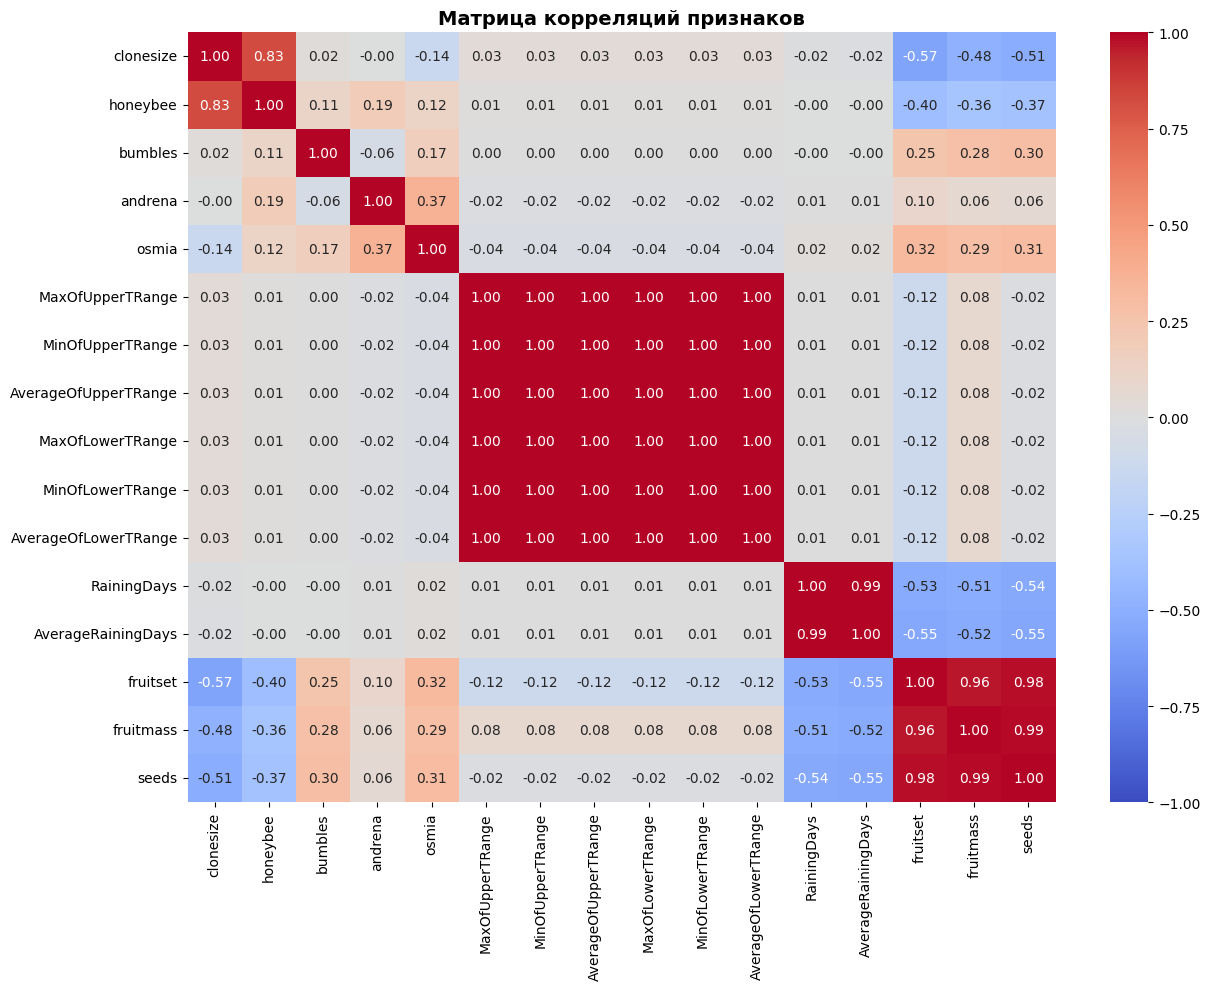

In [133]:
# Считаем матрицу корреляций (убираем целевую переменную yield, чтобы сравнивать только признаки)
features = df_base.drop(columns=['yield'])
corr_matrix = features.corr()

# Строим тепловую карту
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Матрица корреляций признаков", fontsize=14, fontweight='bold')
plt.show()

In [134]:
# Берем верхний треугольник матрицы, чтобы пары не дублировались
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Находим признаки с корреляцией > 0.9
to_drop = [column for column in upper.columns if any(upper[column].abs() > 0.9)]
print("Кандидаты на удаление (корреляция > 0.9):", to_drop)


Кандидаты на удаление (корреляция > 0.9): ['MinOfUpperTRange', 'AverageOfUpperTRange', 'MaxOfLowerTRange', 'MinOfLowerTRange', 'AverageOfLowerTRange', 'AverageRainingDays', 'fruitmass', 'seeds']


### Точная проверка: коэффициент VIF (Variance Inflation Factor)
Корреляция видит только парные связи, а VIF проверяет можно ли предсказать один признак через комбинацию всех остальных. Если VIF > 10, признак избыточен, 1 < VIF < 5 - умеренная связь, VIF ~ 1 признак польностью независим от остальных.

In [136]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Создаем таблицу Х, только с входными признаками
X = df_base.drop(columns=['yield'])

# Создаем пустую таблицу, куда будем записывать результаты
vif_data = pd.DataFrame()

# Создаем столбец и заполняем его
vif_data["Признак"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

# Сортируем от самых избыточных к независимым
print(vif_data.sort_values(by="VIF", ascending=False))

                 Признак                 VIF
6       MinOfUpperTRange 1000799917193443.50
7   AverageOfUpperTRange 1000799917193443.50
5       MaxOfUpperTRange 1000799917193443.50
8       MaxOfLowerTRange 1000799917193443.50
9       MinOfLowerTRange 1000799917193443.50
10  AverageOfLowerTRange 1000799917193443.50
14             fruitmass             1349.68
15                 seeds              802.81
13              fruitset              184.40
12    AverageRainingDays               83.81
11           RainingDays               72.71
0              clonesize                8.50
1               honeybee                4.55
2                bumbles                1.82
4                  osmia                1.79
3                andrena                1.34


C:\Users\denis\AppData\Local\Temp\ipykernel_1004\2502100349.py:11: UserWarning: The design matrix is poorly conditioned (condition number=1.35e+16). VIF calculations may be numerically unstable.
  vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
C:\МАГИСТРАТУРА\Проектный практикум\project\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
C:\МАГИСТРАТУРА\Проектный практикум\project\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
C:\МАГИСТРАТУРА\Проектный практикум\project\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniqu

### **Вывод**
| **Данные** | **Описание** | **Решение:** |
|---------|----------|-------|
| **'MaxOfUpperTRange'**, **'MinOfUpperTRange'**, **'AverageOfUpperTRange'**, **'MaxOfLowerTRange'**,**'MinOfLowerTRange'**, **'AverageOfLowerTRange'** | Все шесть температурных признака обладают абсолютной избыточностью (VIF показал, что все температурные показатели связаны математичекской формулой. | Оставить только одно значение темпертуры, например, **"AverageOfUpperTRange"** |
| **"fruitmass"**, **"fruitset"**, **"seeds"** | Высокая избыточность. Колличество семян, масса ягоды и завязываемость плода зависят друг от друга, больше завязей и семян - больше масса. | Оставить только **"fruitset"**. |
| **"RainingDays"**, **"AverageRainingDays"** | Сильная избыточность. Оба столбца описывают одно и тоже явление. | Оставить один из двух. |
| **Виды шмелей** и **пчел** | У видом пчел и шмелей - признаки независимые. | Все столбцы остаются. |

In [137]:

# 1. Список избыточных столбцов (оставляем по одному из каждой группы)
cols_to_drop = [
    'MinOfUpperTRange', 'MaxOfUpperTRange',
    'MinOfLowerTRange', 'MaxOfLowerTRange', 'AverageOfLowerTRange',
    'RainingDays', 'fruitmass', 'seeds'
]

# Если в таблице остался служебный столбец 'Row#', его тоже лучше убрать:
if 'Row#' in df_base.columns:
    cols_to_drop.append('Row#')

# 2. Создаем финальный датафрейм без лишних столбцов
df_final = df_base.drop(columns=cols_to_drop)

# 3. Проверяем VIF на оставшихся признаках (с добавлением константы)
X_check = sm.add_constant(df_final.drop(columns=['yield']))
vif_final = pd.DataFrame({
    'Признак': X_check.columns[1:],
    'VIF': [variance_inflation_factor(X_check.values, i + 1) for i in range(X_check.shape[1] - 1)]
})

print("Оставшиеся столбцы:", list(df_final.columns))
print("\nИтоговая таблица VIF:")
print(vif_final.sort_values(by='VIF', ascending=False).to_string(index=False))

Оставшиеся столбцы: ['clonesize', 'honeybee', 'bumbles', 'andrena', 'osmia', 'AverageOfUpperTRange', 'AverageRainingDays', 'fruitset', 'yield']

Итоговая таблица VIF:
             Признак  VIF
           clonesize 5.19
            honeybee 4.11
            fruitset 4.05
  AverageRainingDays 2.26
               osmia 1.53
             bumbles 1.28
             andrena 1.26
AverageOfUpperTRange 1.04


In [138]:
# Создаем датафрейм для поиска условий влияния на урожайность
cols_to_drop = ['fruitset']
df_conditions = df_final.drop(columns=cols_to_drop)
print("Оставшиеся столбцы:", list(df_conditions.columns))

Оставшиеся столбцы: ['clonesize', 'honeybee', 'bumbles', 'andrena', 'osmia', 'AverageOfUpperTRange', 'AverageRainingDays', 'yield']


In [139]:
# Создаем датафрейм для понимания механизма увеличения массы урожая
cols_to_drop = [
    'AverageOfUpperTRange', 'AverageRainingDays'
]
df_fruits = df_final.drop(columns=cols_to_drop)
print("Оставшиеся столбцы:", list(df_fruits.columns))

Оставшиеся столбцы: ['clonesize', 'honeybee', 'bumbles', 'andrena', 'osmia', 'fruitset', 'yield']


## Итог

Умеренная корреляция осталась у 'clonesize', 'honeybee', 'fruitset'. 
- df - оригинальный датафрейм с добавдением строк другого моделирования или экстеримальных условий.
- df_base - датафрейм с удаленными строками другой модели и содержащий все столбцы.
- df_conditions - для прогноза урожайности по основным параметрам.
- df_fruits - для прогноза массы урожая.

---

# **Часть 4. Одномерный анализ**

## **4.1 Распределение урожая (целевая переменная)**

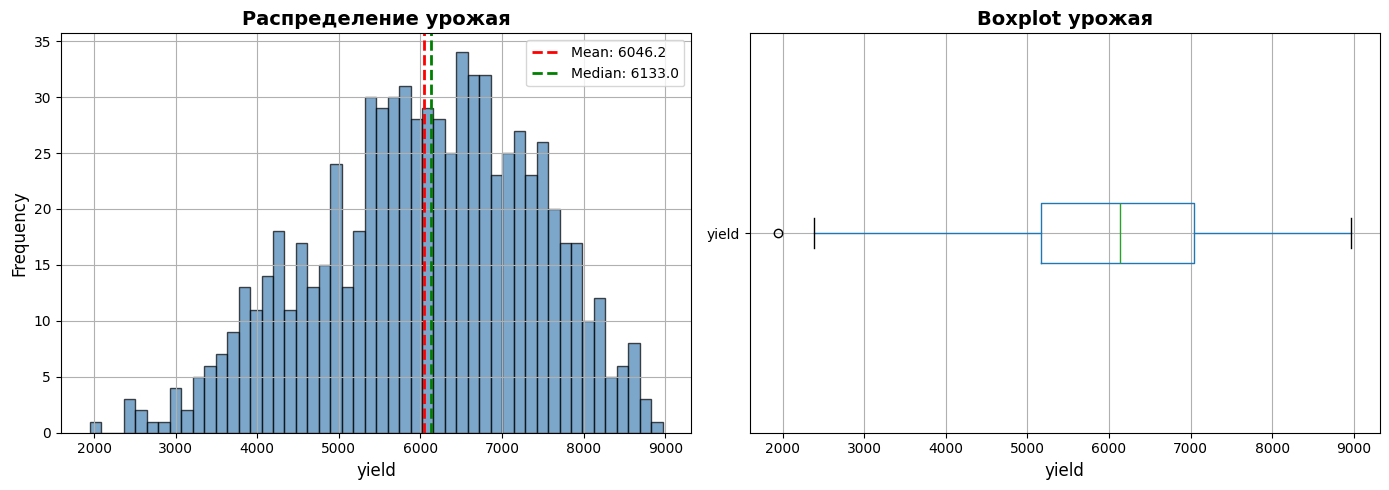

In [147]:
# Гистограмма популярности
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Гистограмма
ax1 = axes[0]
df_conditions['yield'].hist(bins=50, ax=ax1, color='steelblue', edgecolor='black', alpha=0.7)
ax1.axvline(df_conditions['yield'].mean(), 
            color='red', linestyle='--', linewidth=2, label=f'Mean: {df_conditions["yield"].mean():.1f}')
ax1.axvline(df_conditions['yield'].median(), 
            color='green', linestyle='--', linewidth=2, label=f'Median: {df_conditions["yield"].median():.1f}')
ax1.set_xlabel('yield', fontsize=12)
ax1.set_ylabel('Frequency', fontsize=12)
ax1.set_title('Распределение урожая', fontsize=14, fontweight='bold')
ax1.legend(fontsize=10)

# KDE + Boxplot
ax2 = axes[1]
df_conditions.boxplot(column='yield', ax=ax2, vert=False)
ax2.set_title('Boxplot урожая', fontsize=14, fontweight='bold')
ax2.set_xlabel('yield', fontsize=12)


plt.tight_layout()
plt.show()

**Вывод**
- Распределение близко к нормальному, одномодальное (имеет один вырарженный пик в районе 6000-6500, что говорит об однородности данных).
- Среднее и медиана почти совпадают, основаня масса сосредоточена в районе 5300-7100, в диапазоне от 2500 до 9000. Есть один выброс.

## 4.2 Распределение природных параметров

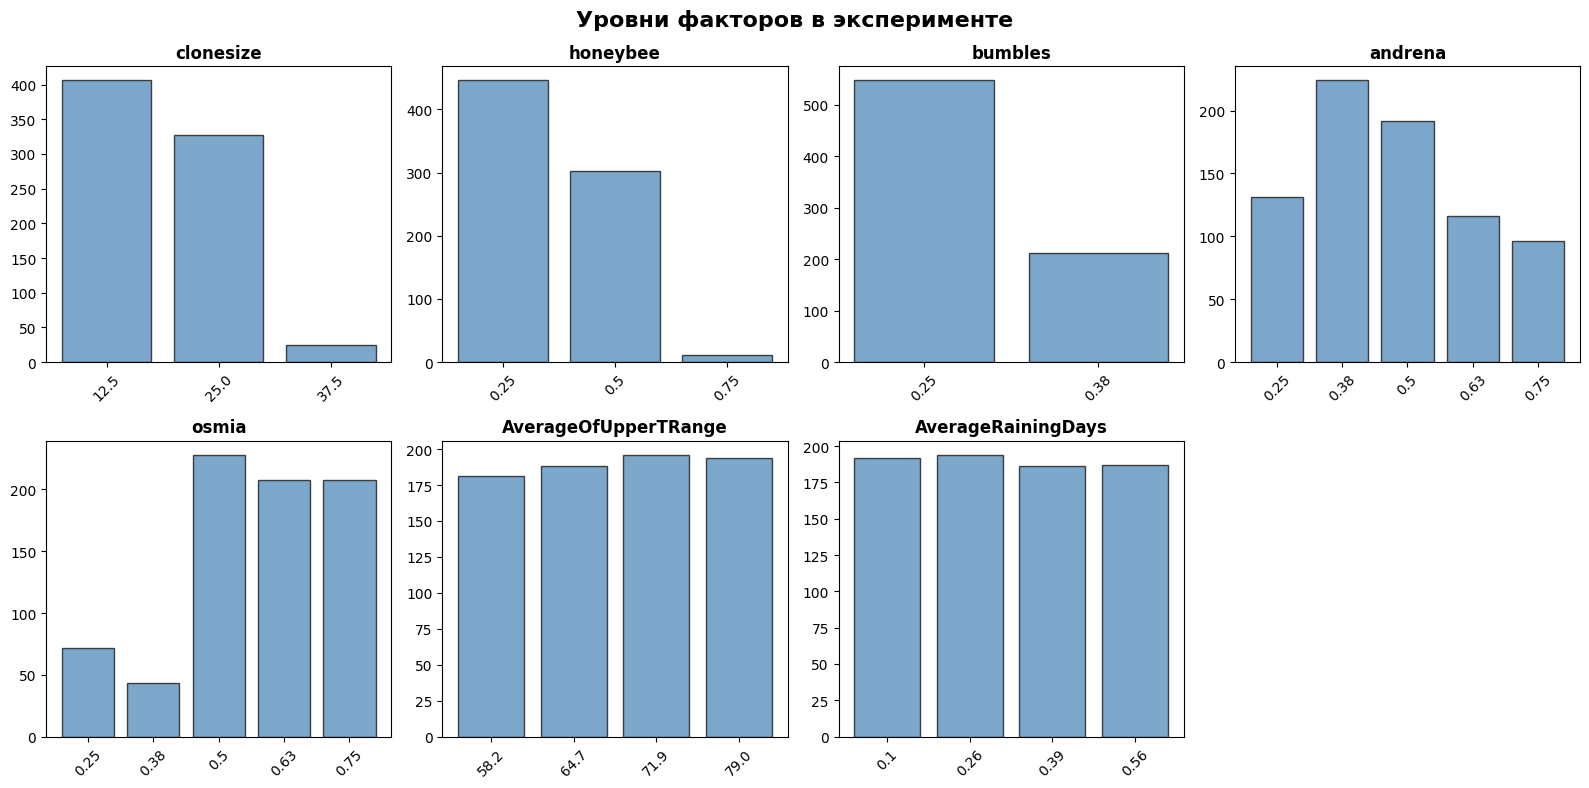

In [158]:
# Параметры дискретные, поэтому вместо гистрограммы столбчатая диаграмма
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, col in zip(axes.flatten(), df_conditions):
    counts = df_conditions[col].value_counts().sort_index()
    ax.bar(counts.index.astype(str), counts.values, color='steelblue', edgecolor='black', alpha=0.7)
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.tick_params(axis='x', rotation=45)
axes.flatten()[-1].set_visible(False)

plt.suptitle('Распределение природных параметров', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

**Вывод**
- 'clonesize', 'honeybee', 'bumbles', 'osmia' - сильно не сбалансированы.
- 'andrena' - умеренно сблалансирован.
'AverageOfUpperTRange', 'AverageRainingDays', 'yield' - хорошо сбалансированы.

In [ ]:
## **4.3 Распределение формирующих непосредственно урожай*

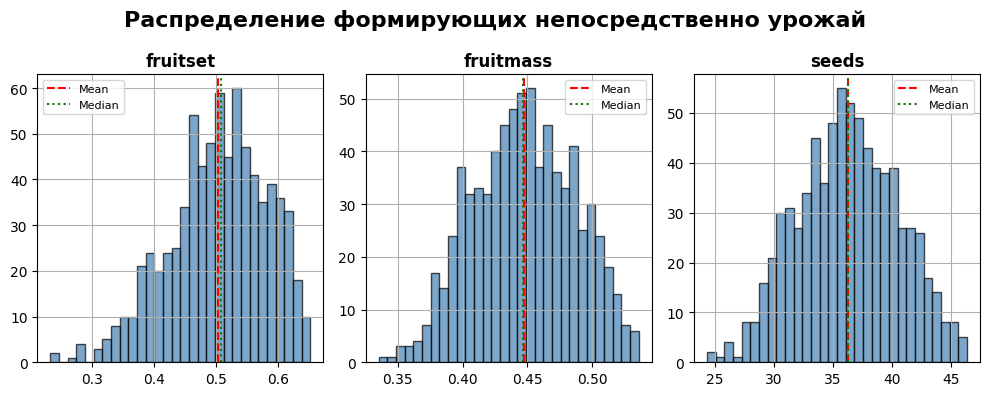

In [178]:
# Параметры дискретные, поэтому вместо гексограмм столбчатая диаграмма
germ = ["fruitset", "fruitmass", "seeds"]
fig, axes = plt.subplots(1, 3, figsize=(10, 4))

for ax, col in zip(axes, germ):
    df_base[col].hist(bins=30, ax=ax, color='steelblue', edgecolor='black', alpha=0.7)
    ax.axvline(df_base[col].mean(), color='red', linestyle='--', label='Mean')
    ax.axvline(df_base[col].median(), color='green', linestyle=':', label='Median')
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.legend(fontsize=8)
plt.suptitle('Распределение формирующих непосредственно урожай', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

**Вывод**
- Распределение близко к нормальному, одномодальное, имеет один вырарженный пик.
- Среднее и медиана почти совпадают.

---

# **Часть 5. Многомерный анализ**

## **5.1 Визуальный анализ взаимосвязей (pairplot)**

**Принцип EDA:** Сначала смотрим, потом считаем!
Pairplot позволяет визуально оценить взаимосвязи до расчёта корреляций.

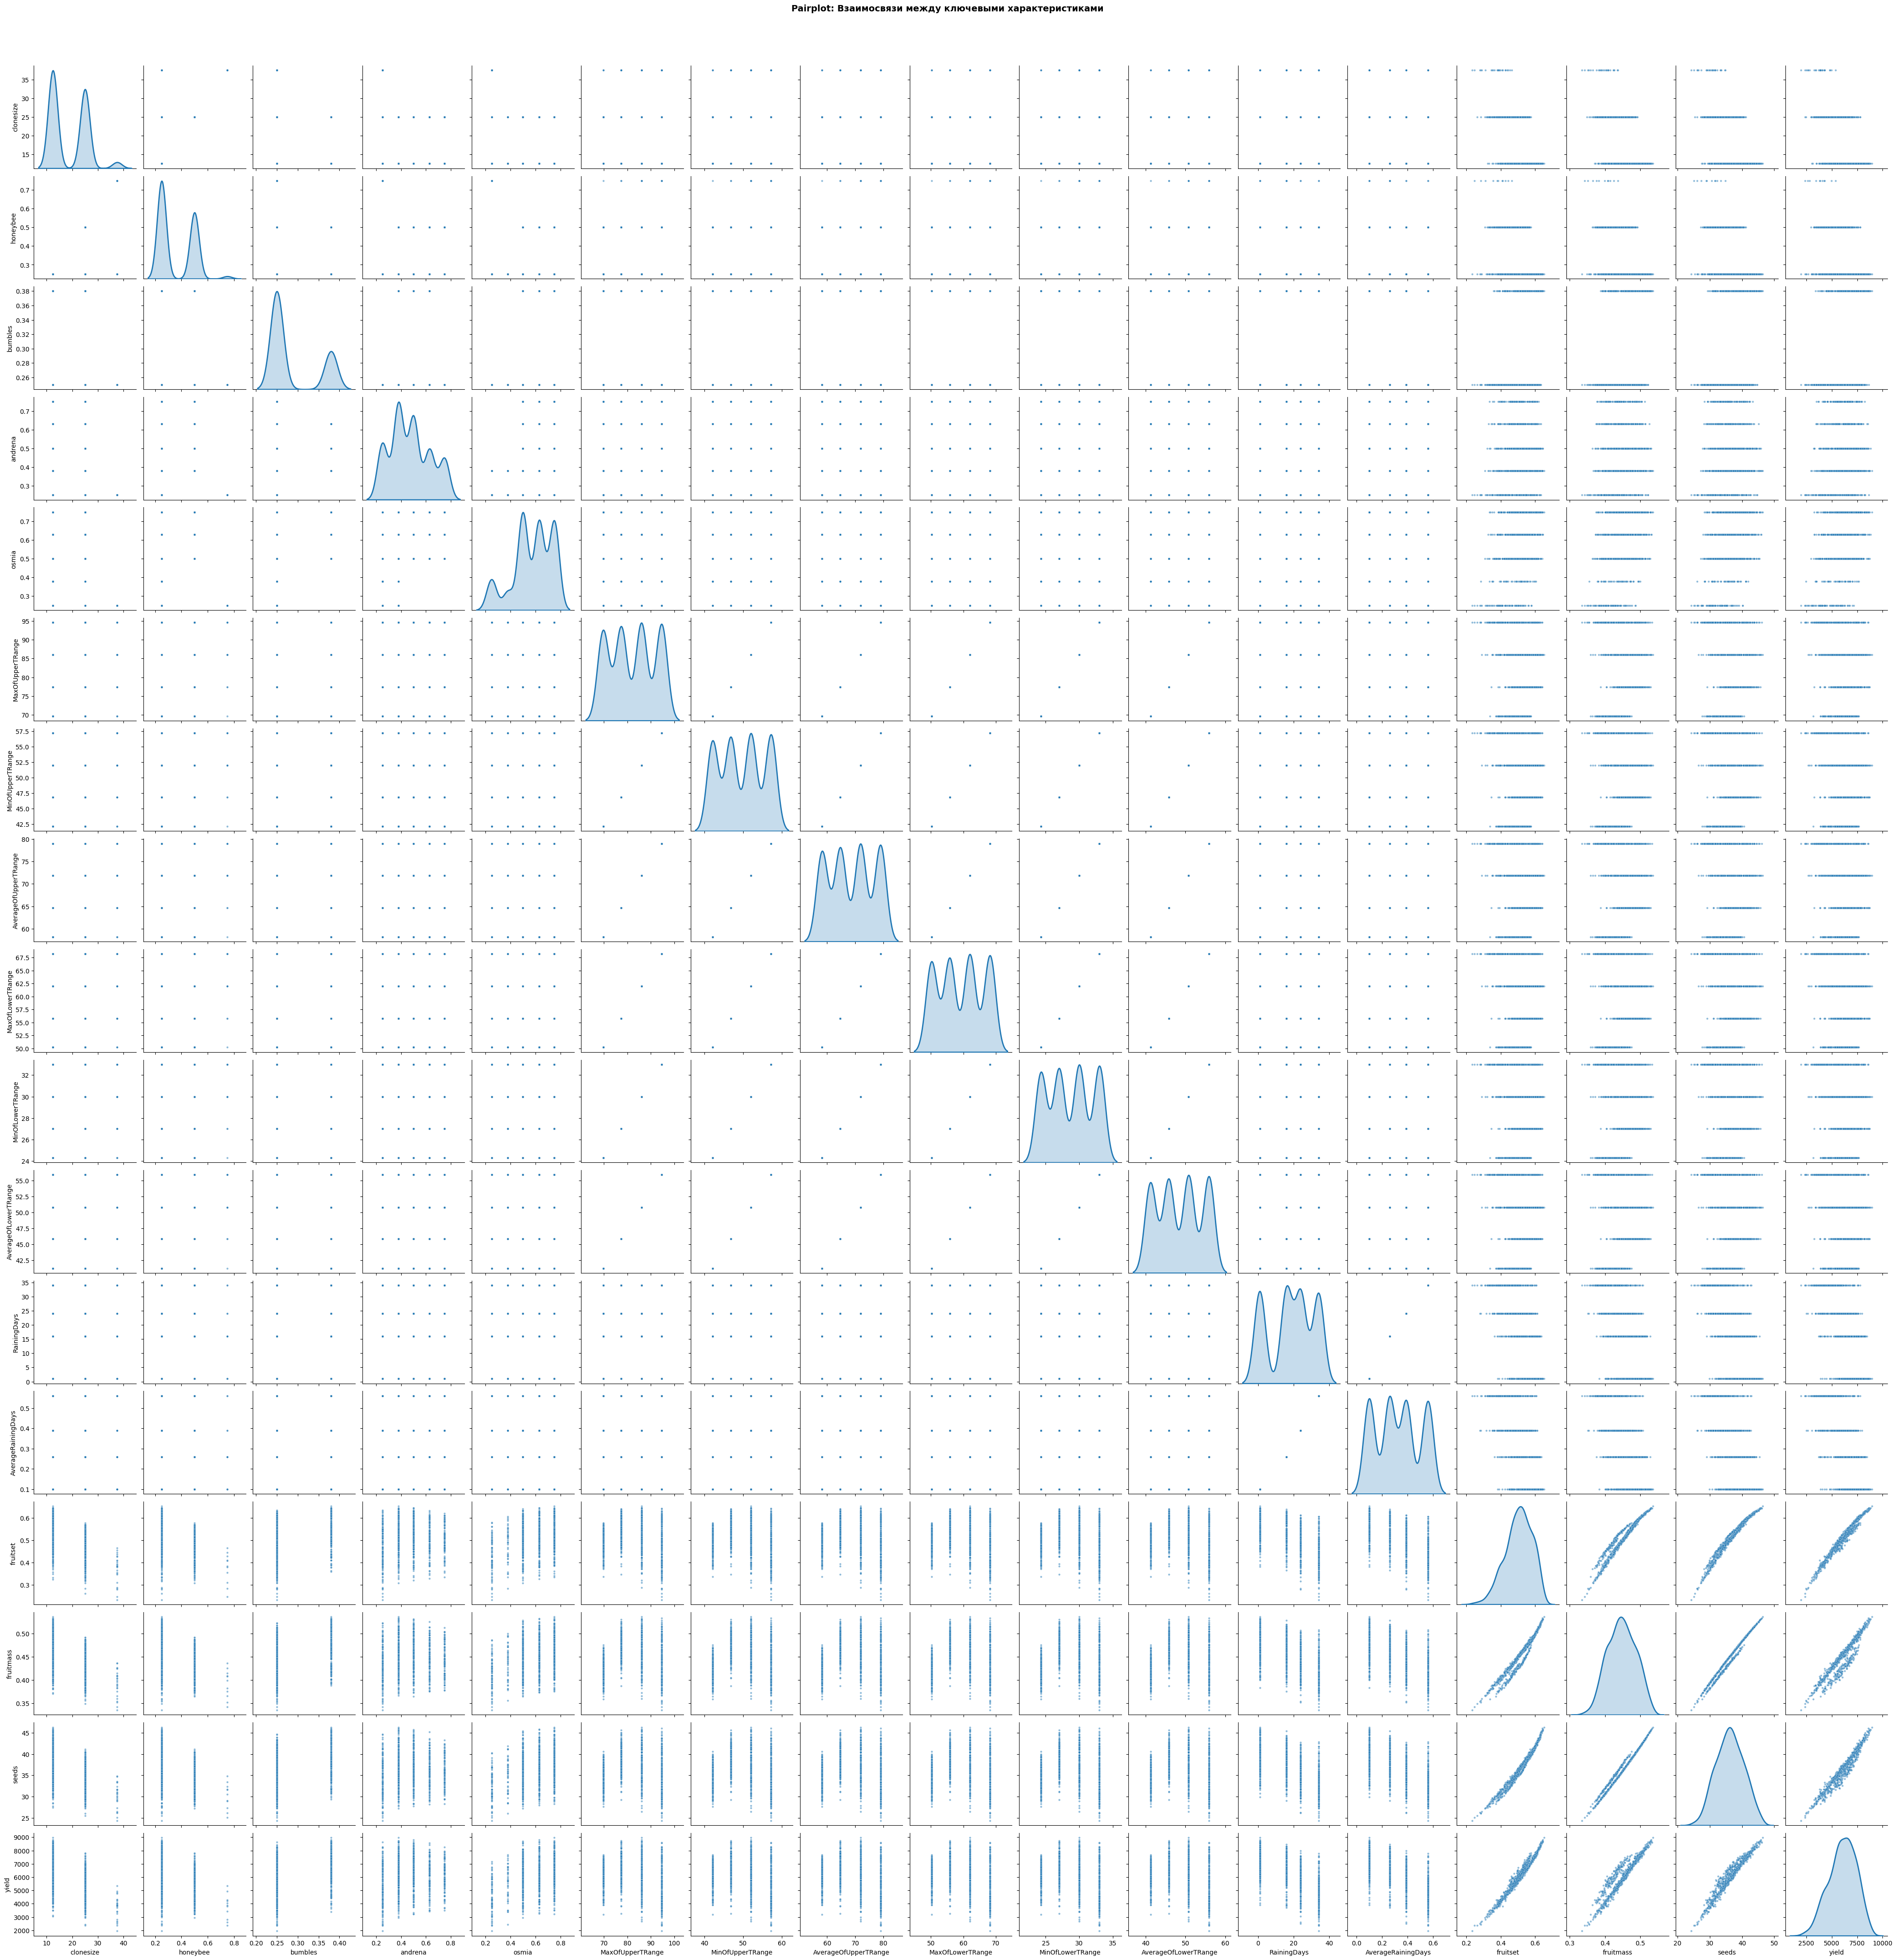

In [180]:
# Pairplot
sns.pairplot(df_base, diag_kind='kde',
             plot_kws={'alpha': 0.5, 's': 10},
             diag_kws={'linewidth': 2})
plt.suptitle('Pairplot: Взаимосвязи между ключевыми характеристиками',
             fontsize=14, fontweight='bold', y=1.02)
plt.show()

**Вывод**
- "fruitset", "fruitmass", "seeds" демонстируют почти идеальную линейную связь, как с целевой переменной, так и между собой.
- Избыточноть погодных признаков, синхронно повторяют 4 дискретных уровня и полностью дублируют друг друга.
- Внешние факторы: опылтители, погода, размер куста формируют итогувую урожайность.

## **5.2 Корреляционный анализ с φk (phik)**

In [182]:
# Импорт библиотеки phik
!pip install phik
import phik
from phik import resources, report

### **Матрица корреляций φk**

Важно: для корректного расчёта φk нужно явно указать интервальные (непрерывные) переменные через параметр interval_cols. Это позволяет библиотеке правильно определить типы переменных и выбрать соответствующий метод расчёта корреляции.

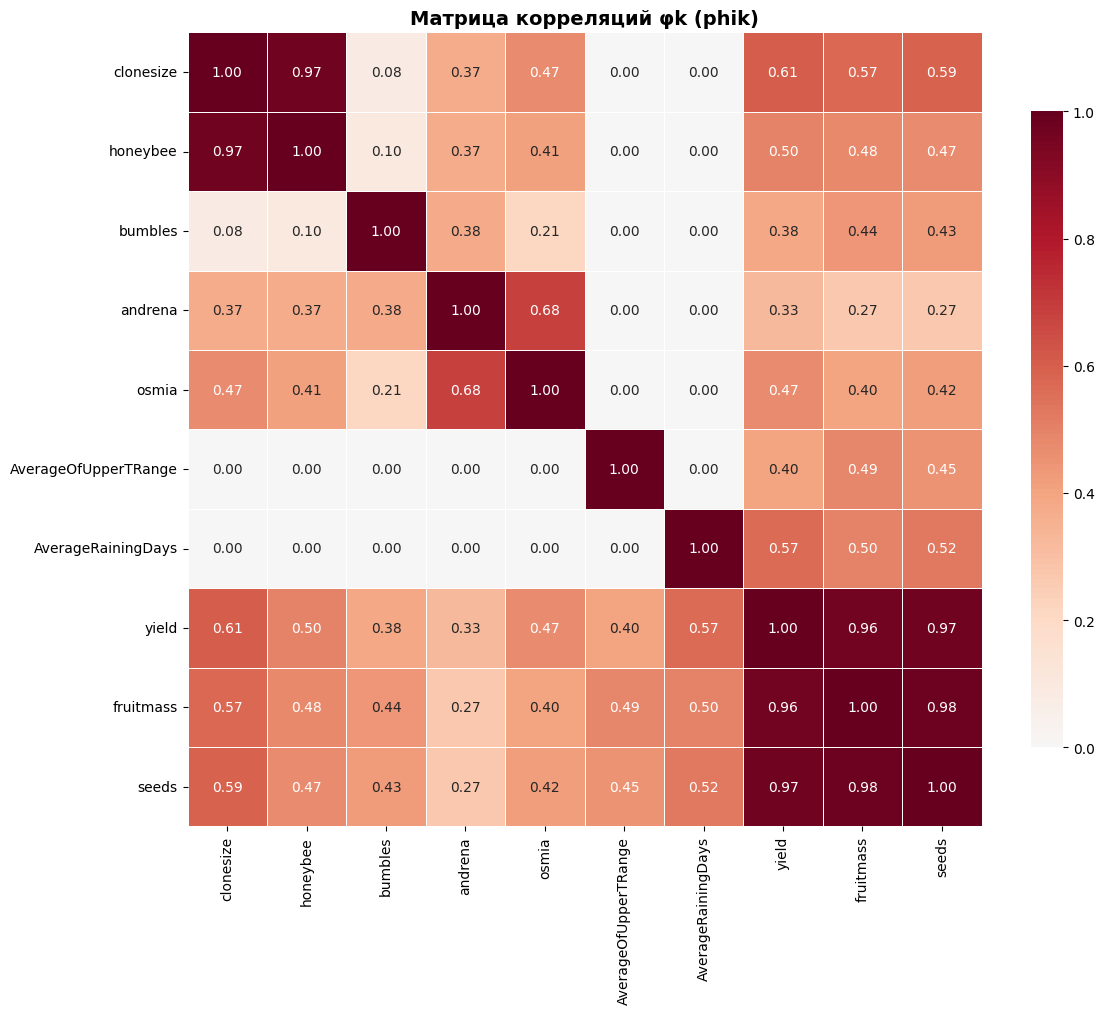

In [192]:
# Определяем интервальные (непрерывные) переменные
interval_cols = ['clonesize', 'honeybee', 'bumbles', 'andrena', 'osmia', 'AverageOfUpperTRange', 'AverageRainingDays', 'yield', "fruitmass", "seeds"]


# Расчёт матрицы phik с явным указанием интервальных переменных
phik_matrix = df_base[interval_cols].phik_matrix(interval_cols=phik_cols)

# Heatmap
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(phik_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            square=True, linewidths=0.5, ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title('Матрица корреляций φk (phik)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


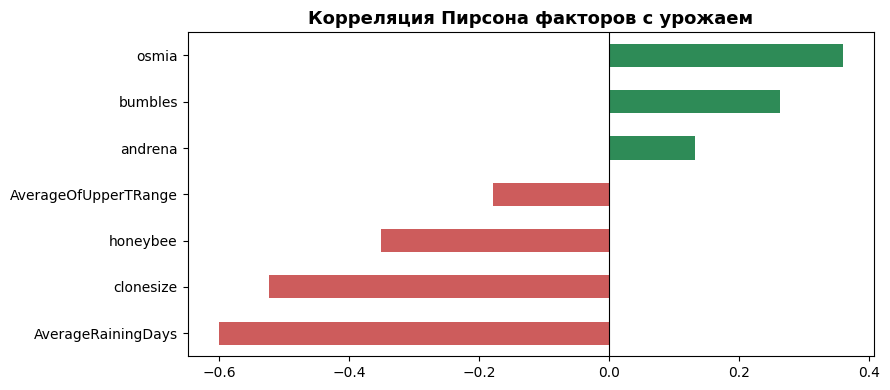

AverageRainingDays     -0.60
clonesize              -0.52
honeybee               -0.35
AverageOfUpperTRange   -0.18
andrena                 0.13
bumbles                 0.26
osmia                   0.36
Name: yield, dtype: float64

In [193]:
pearson = df_conditions.corr()['yield'].drop('yield').sort_values()

fig, ax = plt.subplots(figsize=(9, 4))
pearson.plot(kind='barh', ax=ax, color=['indianred' if v < 0 else 'seagreen' for v in pearson])
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Направление корреляции', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

pearson.round(3)

**Вывод**
- Наибольшее влияние среди внешних факторов оказывают доля дождливых дней и размер клона.
- дикие опылители положительно влияют на урожай, лидирует osmia.
- Отрицательная корреляция honeybee c урожаем объясняется жесткой связью между "honeybee" и "clonesize" в плане эксперимента.  "honeybee" и "clonesize" корреляция 0,97, это значит, что в плане эксперимента плотность медоносных пчел менялась не независимо, а пропроционально размеру куста. Надо проверить.
    

Таблица сопряженности (количество наблюдений):
honeybee   0.25  0.50  0.75
clonesize                  
12.50       406     0     0
25.00        26   302     0
37.50        14     0    11


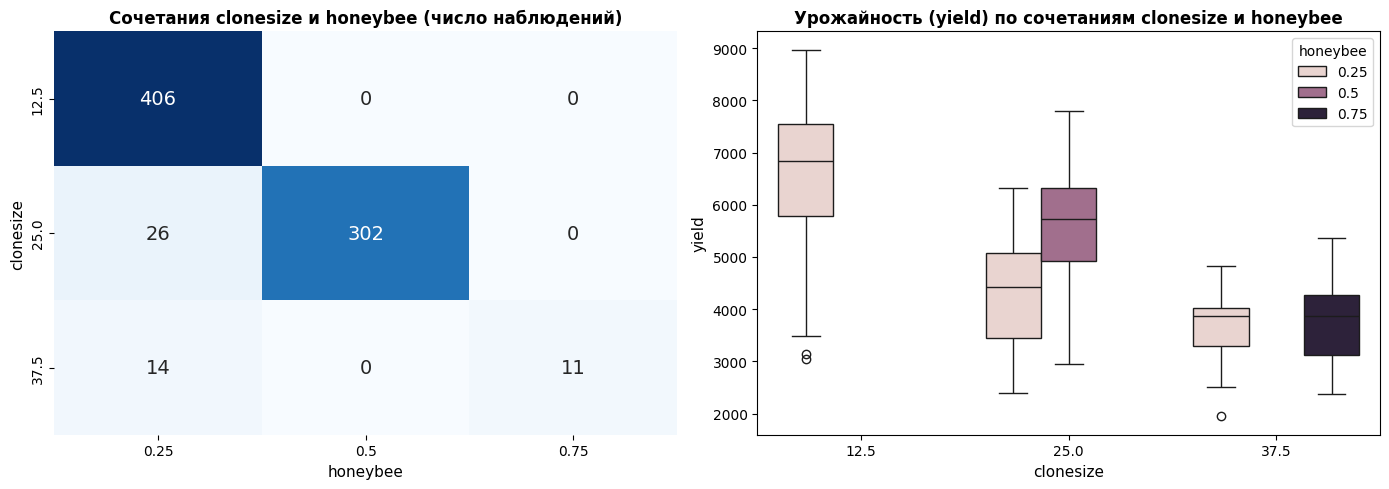

In [196]:
# 1. Таблица сопряженности (сколько наблюдений попадает в каждую пару значений)
ct = pd.crosstab(df_conditions['clonesize'], df_conditions['honeybee'])
print("Таблица сопряженности (количество наблюдений):")
print(ct)

# 2. Визуализация в виде тепловой карты и сравнение урожайности по парам
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График 1: Тепловая карта частот
sns.heatmap(ct, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False, annot_kws={"size": 14})
axes[0].set_title('Сочетания clonesize и honeybee (число наблюдений)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('honeybee', fontsize=11)
axes[0].set_ylabel('clonesize', fontsize=11)

# График 2: Распределение урожая (yield) внутри каждого сочетания
sns.boxplot(data=df_conditions, x='clonesize', y='yield', hue='honeybee', ax=axes[1])
axes[1].set_title('Урожайность (yield) по сочетаниям clonesize и honeybee', fontsize=12, fontweight='bold')
axes[1].set_xlabel('clonesize', fontsize=11)
axes[1].set_ylabel('yield', fontsize=11)
axes[1].legend(title='honeybee')

plt.tight_layout()
plt.show()

In [ ]:
**Вывод**
- Связанный дизайн эксперимента. (12.5 к 0.25, 25.0 к 0.50, 37,5 к 0.75).
- Общая отрицательная корреляция с урожаем является ложной и вызвана тем, высокие концентрации пчел тестировались только на
больших клонах с низкой урожайностью.
- Реальное влиянием медоносных пчел - положительно, на одинаковых клонах.

---

# **Часть 6. Сегментированный анализ**
Подготовка для построения лепестковой диаграммы.

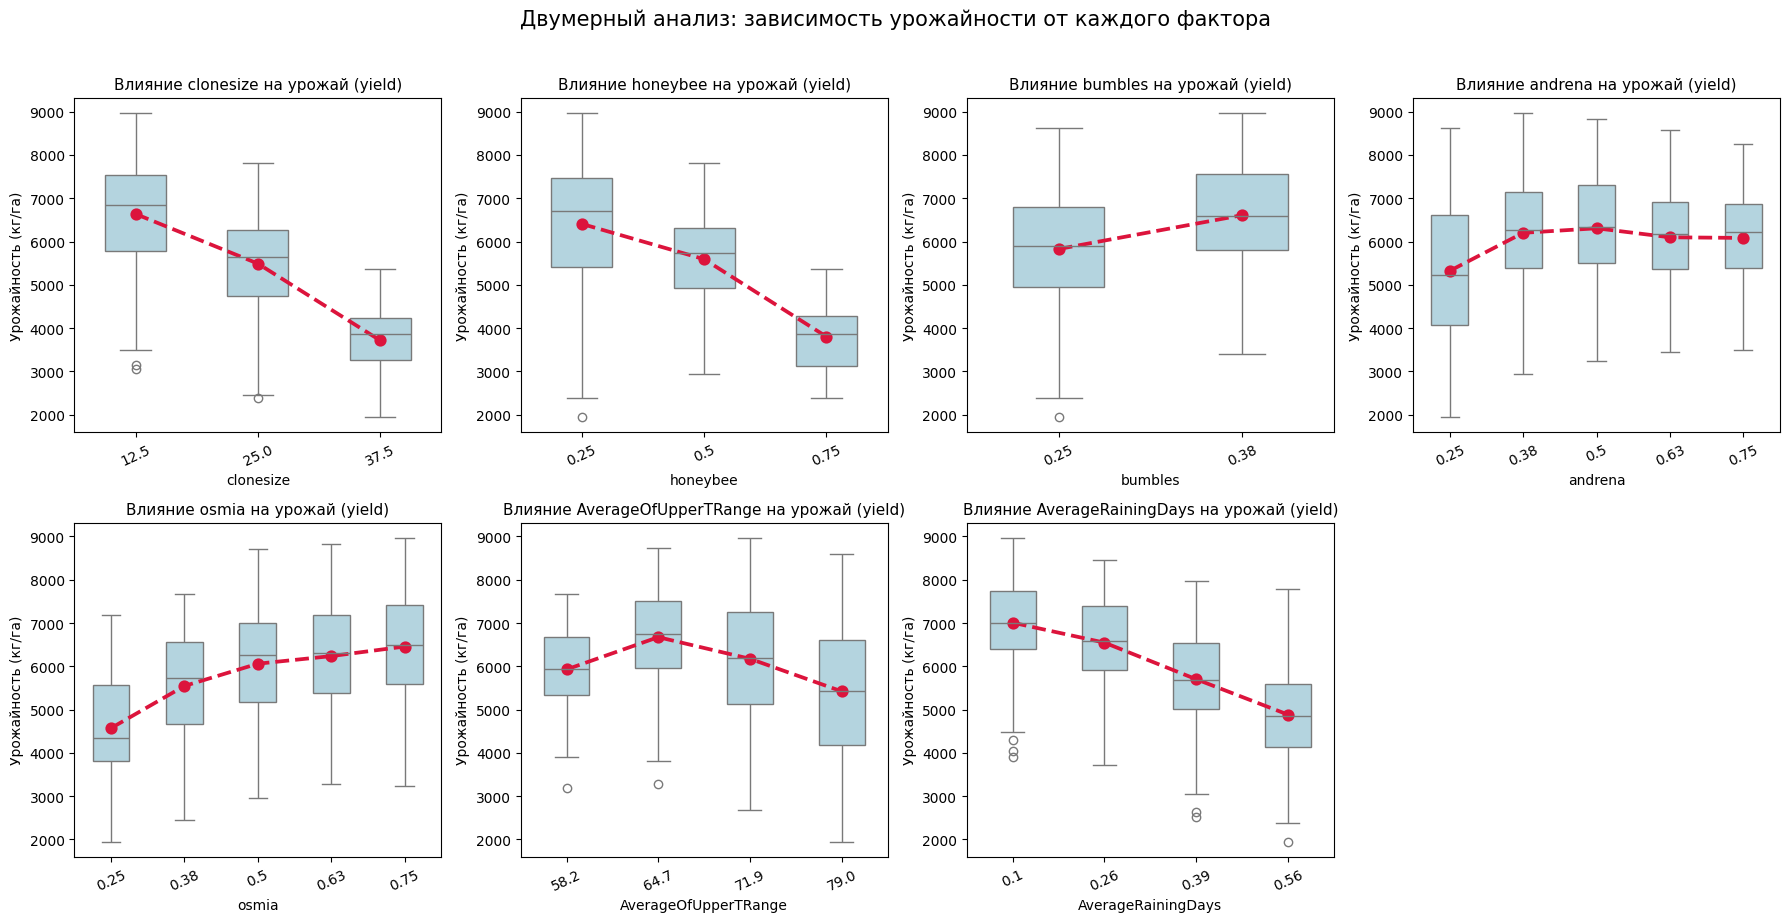

In [200]:
# Двумерный анализ: зависимость урожайности от каждого фактора
factors = [
    'clonesize',
    'honeybee',
    'bumbles',
    'andrena',
    'osmia',
    'AverageOfUpperTRange',
    'AverageRainingDays',
]

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for i, col in enumerate(factors):
  # 1. Ящик с усами показывает разброс и медиану для каждого значения фактора
  sns.boxplot(
      data=df_conditions,
      x=col,
      y='yield',
      ax=axes[i],
      color='lightblue',
      width=0.5,
  )
  # 2. Pointplot поверх ящиков соединяет средние значения красной линией тренда
  sns.pointplot(
      data=df_conditions,
      x=col,
      y='yield',
      ax=axes[i],
      color='crimson',
      markers='o',
      linestyles='--',
      errorbar=None,
  )

  axes[i].set_title(f'Влияние {col} на урожай (yield)', fontsize=11)
  axes[i].set_xlabel(col)
  axes[i].set_ylabel('Урожайность (кг/га)')
  axes[i].tick_params(axis='x', rotation=25)

# Скрываем восьмую пустую ячейку
axes[-1].set_visible(False)

plt.suptitle(
    'Двумерный анализ: зависимость урожайности от каждого фактора',
    fontsize=15,
    y=1.02,
)
plt.tight_layout()
plt.show()


## **6.2 «Что может способствовать повышению урожая?»**

In [207]:
# Определяем долю высоких урожаев
high_threshold = df_conditions['yield'].quantile(0.75)
df_conditions['is_high'] = (df_conditions['yield'] >= high_threshold).astype(int)

print(f"Порог высокого урожая: yield >= {high_threshold:.0f}")
print(df_conditions['is_high'].value_counts())
print(f"\nДоля высоких: {df_conditions['is_high'].mean() * 100:.1f}%")

Порог высокого урожая: yield >= 7043
is_high
0    569
1    190
Name: count, dtype: int64

Доля высоких: 25.0%


In [209]:
# Находим разницу в сравнении с высоким
high_comparison = df_conditions.groupby('is_high')[factors].median().T
high_comparison.columns = ['Обычные поля', 'Высокий урожай']
high_comparison['Разница'] = high_comparison['Высокий урожай'] - high_comparison['Обычные поля']
high_comparison['Разница %'] = ((high_comparison['Высокий урожай'] / high_comparison['Обычные поля'] - 1) * 100).round(1)
high_comparison.round(3)

,Обычные поля,Высокий урожай,Разница,Разница %
clonesize,25.00,12.50,-12.50,-50.00
honeybee,0.50,0.25,-0.25,-50.00
bumbles,0.25,0.25,0.00,0.00
andrena,0.50,0.50,0.00,0.00
osmia,0.63,0.63,0.00,0.00
AverageOfUpperTRange,71.90,68.30,-3.60,-5.00
AverageRainingDays,0.39,0.26,-0.13,-33.30


Факторы в разных единицах, поэтому их надо нормировать, и прривести к диапазон 0-1, берем средние вместо медиан, потому что некоторые параметры дискретные, а среднее чувствительно к изменению пропроций, что хорошо подходит для лепестковой диаграммы.

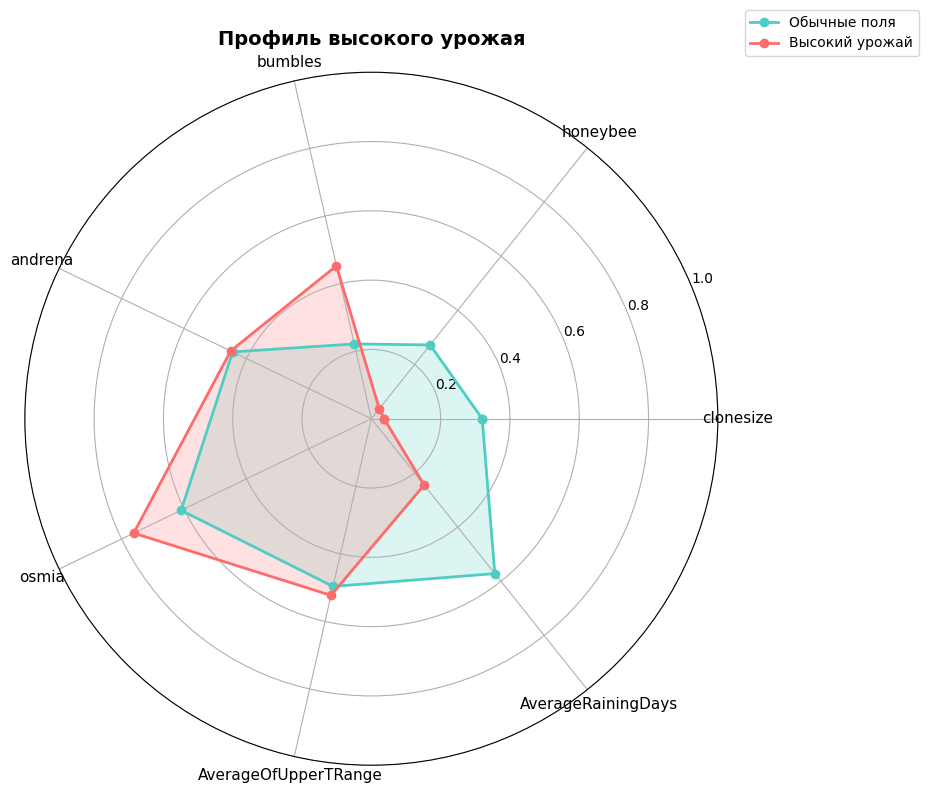

In [211]:
norm = df_conditions[factors].copy()
norm = (norm - norm.min()) / (norm.max() - norm.min())
norm['is_high'] = df_conditions['is_high']
profile_stats = norm.groupby('is_high')[factors].mean()

N = len(factors)
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True))
for label, name, color in [(0, 'Обычные поля', '#4ECDC4'), (1, 'Высокий урожай', '#FF6B6B')]:
    values = profile_stats.loc[label].tolist()
    values += values[:1]
    ax.plot(angles, values, 'o-', linewidth=2, label=name, color=color)
    ax.fill(angles, values, alpha=0.2, color=color)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(factors, fontsize=11)
ax.set_ylim(0, 1)
ax.set_title('Профиль высокого урожая', fontsize=14, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.show()

In [ ]:
**Вывод**
- Для достижения высокого урожая нужны компактные поля, больше шмелей и осмий и меньше дождлливых дней.

In [213]:
# Пример для самого сильного положительного фактора (osmia) и отрицательного (RainingDays)
for col in ['bumbles', 'osmia', 'AverageRainingDays', 'clonesize']:
  summary = df_conditions.groupby(col)['yield'].agg(
      количество_строк='count',
      средний_урожай='mean',
      медиана='median',
      разброс_std='std',
  )
  print(f'\n--- Влияние фактора: {col} ---')
  print(summary.round(1))


--- Влияние фактора: bumbles ---
         количество_строк  средний_урожай  медиана  разброс_std
bumbles                                                        
0.25                  547         5827.80  5902.30      1312.70
0.38                  212         6609.70  6601.00      1238.00

--- Влияние фактора: osmia ---
       количество_строк  средний_урожай  медиана  разброс_std
osmia                                                        
0.25                 72         4572.10  4337.80      1264.90
0.38                 43         5545.50  5739.90      1284.60
0.50                228         6059.70  6253.20      1238.20
0.63                208         6235.40  6303.80      1216.50
0.75                208         6456.00  6493.60      1225.00

--- Влияние фактора: AverageRainingDays ---
                    количество_строк  средний_урожай  медиана  разброс_std
AverageRainingDays                                                        
0.10                             192         7007

**Выводы**
- Размер клона, самый сильный фактор падения урожая.
- Кол-во дождяя сильно влияет на урожай.
- Увеличение плотности шмелей положительно влияет на урожайность, они, в отличии от пчел могут летать в более прохладную и дождливую погоду.
- Сильный эффект дает увеличение осмий, но до определенного кол-ва, далее наступает эффект насыщения и прирост уже слаыбый.

## Общие выводы

#### **1. Борьба с мультиколлинеарностью и утечками.**
- Из 6 температурных столбцов и 2 столбцов осадков достаточно оставить по одному представителю (AverageOfUpperTRange и RainingDays), так как остальные дублируют их на 99–100%.
- Промежуточные показатели опыления (fruitset, fruitmass, seeds) имеют корреляцию 0.96–0.97 с урожаем — их нельзя использовать при прогнозировании урожая до цветения (утечка данных), но можно использовать для оценки урожая после завязи ягод.
- Учёт дизайна эксперимента при валидации. В данных есть жёсткая связка clonesize — honeybee (phi_k = 0.97) и редкие уровни факторов (например, всего 25 строк с clonesize = 37.5 и 43 строки с osmia = 0.38). При разделении выборки на train и test необходимо использовать стратификацию по ключевым дискретным факторам, чтобы редкие сценарии равномерно попали в обе выборки.

#### **2. Выводы и рекомендации для агробизнеса (фермеров)**
- Проектирование посадок — главный рычаг (clonesize).
Рекомендация: Высаживать голубику компактными куртинами (клонами размером около 12.5 м²), чередуя разные сорта рядом друг с другом для перекрёстного опыления.
- Экономический эффект: Слишком крупные однородные массивы (25–37.5 м²) снижают медианный урожай на 1100–2900 кг/га, так как пчёлы летают внутри одного клона и не долетают до клонов с другими видами черники.
- Привлекать и разводить диких пчёл — осмий (osmia) и шмелей (bumbles) (установка домиков-ульев для осмий, сохранение диких медоносов по краям полей).
- Экономический эффект (точка оптимума): Самый выгодный скачок урожая (+1400 кг/га) происходит при подъёме плотности осмий с минимального уровня (0.25) до умеренного (0.38–0.50). Дальнейшее наращивание до максимума (0.75) даёт уже скромную прибавку (+240 кг/га) и может не окупить затраты, а вот добавление шмелей помогает пробить планку рекордных урожаев (выше 7000 кг/га).
- Погода — неуправляемый фактор, но критический порог известен: при более чем 20–24 дождливых днях за период цветения урожайность обваливается на 25–30%. В дождливых регионах ставка на шмелей и осмий становится обязательной, так как они продолжают летать в прохладную и пасмурную погоду, когда медоносные пчёлы сидят в ульях.